# Tutorial 03 — Asteroid thermal model: a generic body on a Keplerian orbit

This notebook runs PTM3D's **generic-body** ("asteroid") thermal path end to
end, from a config file to a physically-interpreted plot, using the CPU core
and the repository's `ptm` Python package.

**Companion .yaml files:**
[`examples/quickstart_asteroid_diurnal.yaml`](../../../examples/quickstart_asteroid_diurnal.yaml)
(TI = 100 SI) and
[`examples/quickstart_asteroid_diurnal_ti200_check.yaml`](../../../examples/quickstart_asteroid_diurnal_ti200_check.yaml)
(TI = 200 SI, otherwise identical — used in Section 3 to confirm a
thermophysical edit reached the solver).

**Cost:** two ~25–35 s CPU-only runs (1280-face icosphere, 2 rotations of
output after a 50-rotation equilibration) — a few minutes total including
plotting, laptop-friendly. Needs the `ptm` package: `pip install -e .` from
the repository root.

**Related tutorials:** [02 — lunar diurnal run](../02_lunar_diurnal_icosphere.md)
(a *built-in* body, for contrast), [06 — interpreting the outputs](../06_interpreting_outputs.md)
(the binary-format reference), and
[`docs/KNOWN_LIMITATIONS.md`](../../KNOWN_LIMITATIONS.md) (which
thermophysical config keys are read on each body type — see Section 2).

## Learning goals

By the end of this notebook you will be able to:

1. Configure and run PTM3D's **generic-body** (Keplerian-orbit, non-built-in
   body) thermal path, and state what external data it does and does not
   need.
2. Know which config section reaches the solver for a generic body
   (`generic_body.surface:`, not a top-level `thermophysical:` block), why
   the run banner cannot confirm a thermal-inertia edit, and how to confirm
   one with a two-run comparison.
3. Read every file PTM3D writes to an output directory through one object,
   `ptm.Results`.
4. Produce the three standard asteroid-thermophysics plots: a surface
   temperature map at one epoch, the equatorial diurnal temperature curve,
   and the **thermal-inertia signature plot** — the morning/afternoon
   asymmetry that is the observable behind asteroid radiometry and the
   Yarkovsky effect.
5. Connect thermal inertia to real observations, and know which knobs
   (thermal inertia, spin rate, orbital eccentricity) to turn next.


## 1. Environment check

A Keplerian-orbit generic body needs no SPICE planetary ephemeris and no DEM:
the orbit is propagated analytically (two-body Kepler), and the shape is a
synthetic icosphere generated at run time — unlike the Moon/Horizons
quickstarts, which need 44 MB–1.1 GB of SPICE kernel data before they can
run.

The one piece of external data required is the **universal leapseconds
kernel** (`naif0012.tls`, ~5 KB): even Keplerian mode uses SPICE's
`str2et_c` to parse the config's UTC `start_time`, and that call fails
without it (`FATAL: SPICE str2et_c failed ... SPICE(NOLEAPSECONDS)`). The
cell below fetches and hash-verifies it if missing.


In [1]:
import hashlib
import subprocess
import sys
import time
from pathlib import Path

try:
    import ptm
except ImportError:
    raise SystemExit(
        "The `ptm` package is not importable. Install it from the repository "
        f"root -- it brings numpy, matplotlib and PyYAML with it:\n"
        f"    {sys.executable} -m pip install -e .")

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import yaml

from ptm import Results, paths, plots
from ptm import run as engine

print("Python     :", sys.version.split()[0])
print("ptm        :", ptm.__version__)
print("numpy      :", np.__version__)
print("matplotlib :", matplotlib.__version__)

REPO_ROOT = paths.find_repo_root(Path.cwd())
if REPO_ROOT is None:
    raise SystemExit("Open this notebook from inside a PTM3D checkout, or set "
                     "$PTM_ROOT.")
print("Repo root  :", REPO_ROOT)

Python     : 3.8.18
ptm        : 0.2.0
numpy      : 1.24.4
matplotlib : 3.7.5
Repo root  : /Users/paha3326/Projects/ptm-ux5a


In [2]:
BIN = paths.find_engine_executable("ptm_thermal_sim", search_roots=[REPO_ROOT])
if BIN is None:
    raise SystemExit(
        f"ptm_thermal_sim not found in {REPO_ROOT}/build/bin (nor in "
        "$PTM_BUILD_DIR). Build the CPU-only core first -- INSTALL.md "
        "'TL;DR (Linux/macOS, CPU-only)':\n"
        "  cmake -S . -B build -DCMAKE_BUILD_TYPE=Release -DPTM_ENABLE_GPU=OFF \\\n"
        "        -DPTM_ARCH_NATIVE=OFF -DCSPICE_ROOT=/path/to/cspice\n"
        "  cmake --build build --target ptm_thermal_sim -j")

commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=str(REPO_ROOT),
                        capture_output=True, text=True).stdout.strip()
help_run = subprocess.run([str(BIN), "--help"], capture_output=True, text=True)

print("Binary     :", BIN)
print("  md5      :", hashlib.md5(BIN.read_bytes()).hexdigest())
print("  commit   :", commit or "(git rev-parse failed -- not fatal)")
print("  --help rc:", help_run.returncode, "(0 = OK)")
assert help_run.returncode == 0, "ptm_thermal_sim --help did not exit 0 -- broken build"
print("\nThis tutorial runs the CPU core throughout (thermal.use_gpu: false in both configs).")

Binary     : /Users/paha3326/Projects/ptm-ux5a/build/bin/ptm_thermal_sim
  md5      : 96b7dca84d25df4d31d21e246632fe58
  commit   : 83d45f6
  --help rc: 0 (0 = OK)

This tutorial runs the CPU core throughout (thermal.use_gpu: false in both configs).


In [3]:
import urllib.request

LSK = REPO_ROOT / "data" / "kernels" / "lsk" / "naif0012.tls"
LSK_URL = "https://naif.jpl.nasa.gov/pub/naif/generic_kernels/lsk/naif0012.tls"
# Pinned; matches scripts/fetch_kernels.py's own pinned hash for this file.
LSK_SHA256 = "678e32bdb5a744117a467cd9601cd6b373f0e9bc9bbde1371d5eee39600a039b"

LSK.parent.mkdir(parents=True, exist_ok=True)
if LSK.exists() and hashlib.sha256(LSK.read_bytes()).hexdigest() == LSK_SHA256:
    print("Leapseconds kernel already present and hash-verified:", LSK)
else:
    print("Fetching the universal leapseconds kernel (one-time, ~5 KB)...")
    urllib.request.urlretrieve(LSK_URL, LSK)
    digest = hashlib.sha256(LSK.read_bytes()).hexdigest()
    assert digest == LSK_SHA256, f"sha256 mismatch: got {digest}, expected {LSK_SHA256}"
    print("Verified sha256:", digest)

print(f"\nTotal external data this tutorial required: 1 file, {LSK.stat().st_size} bytes.")
print("No SPICE planetary/lunar ephemeris, no DEM, no albedo/property maps —")
print("confirmed directly in the config walkthrough below (ephemeris_source: keplerian,")
print("generic_body.config_file: '', use_albedo_map: false).")

Leapseconds kernel already present and hash-verified: /Users/paha3326/Projects/ptm-ux5a/data/kernels/lsk/naif0012.tls

Total external data this tutorial required: 1 file, 5257 bytes.
No SPICE planetary/lunar ephemeris, no DEM, no albedo/property maps —
confirmed directly in the config walkthrough below (ephemeris_source: keplerian,
generic_body.config_file: '', use_albedo_map: false).


## 2. Config walkthrough

The full config, as shipped:

In [4]:
cfg_path = REPO_ROOT / "examples" / "quickstart_asteroid_diurnal.yaml"
print(cfg_path.read_text())

# PTM3D quickstart: a generic-body (Keplerian) asteroid diurnal run on a small
# icosphere (ico3, 1280 faces).
#
# Laptop-friendly (CPU-only, <1 GB RAM; ~23 s measured on an 8-core machine
# with thermal.threads=4, well under a minute of wall time).
# SELF-CONTAINED: unlike the Moon/Horizons quickstarts, this run needs NO
# external data at all — no SPICE kernels, no DEM, no albedo/property maps.
# The body is fictional (there is no real "Quickstart Asteroid"); its orbit is
# propagated analytically (Keplerian two-body) and its shape is a synthetic
# icosphere, so nothing outside this file is fetched or required.
#
# All paths are relative — run FROM THE REPOSITORY ROOT:
#
#     ./build/bin/ptm_thermal_sim --config examples/quickstart_asteroid_diurnal.yaml
#
# Outputs land in output/quickstart_asteroid_diurnal/ (per-face statistics +
# per-timestep binaries). See docs/tutorials/notebooks/03_asteroid_thermal.ipynb
# for a full walkthrough of the outputs.
#
# ----------------------------

### Shape, orbit, spin

- **Shape**: a synthetic icosphere, `resolution: 3` (level-3 subdivision =
  1280 faces) — small enough to run on a laptop CPU in seconds.
- **Orbit** (`generic_body.orbit`): `a = 2.7 AU`, `e = 0` (circular — an
  eccentric variant is Exercise 3), `i = 8°` — a *generic* mid-main-belt
  placement (between Vesta at 2.36 AU and the Themis family near 3.1 AU),
  not tuned to any real object. The solar constant there is
  $S = 1361/2.7^2 \approx 187\ \mathrm{W\,m^{-2}}$ — about 7.3% of Earth's —
  which is why thermal-infrared radiometry, not visible photometry alone, is
  how asteroid surface properties are measured: these bodies are cold and,
  being dark, comparatively IR-bright.
- **Spin** (`generic_body.spin`): `period_hours = 5.0` (a fast rotator,
  typical of a small NEA/main-belt fragment) with `pole_dec_deg = 90` —
  **zero obliquity**, pinning the sub-solar latitude at the equator for the
  whole run so the only time-dependence at this orbit-frozen, sub-day
  timescale is the diurnal cycle.

### Thermophysical properties

**Thermal inertia**,
$$TI = \sqrt{k \, \rho \, c_p} \quad \left[\mathrm{J\,m^{-2}\,K^{-1}\,s^{-1/2}}\right],$$
is *the* asteroid-surface property radiometry measures: it controls how much
a surface's temperature **lags** a fast-varying insolation cycle, the basis
of regolith/rock/bare-rock discrimination (Delbo et al. 2007, 2015).

The config sets `ks = kd = 0.008333 W/m/K`, `rhos = rhod = 1500 kg/m³`,
`cp0 = 800 J/kg/K`, `chi = 0` (no $T^3$ radiative-conductivity enhancement),
giving

$$TI = \sqrt{0.008333 \times 1500 \times 800} = 100.0\ \mathrm{SI\ exactly},$$

constant with depth *and* temperature — `ks == kd` and `rhos == rhod`
collapse PTM3D's usual two-layer regolith profile to one homogeneous slab,
so there is exactly one TI number to reason about. TI = 100 sits in the
textbook regolith range (loose lunar-like regolith ≈ 50 SI, bare
rock/boulders ≈ 400–2500 SI). TI values far outside roughly 32–316 SI can
hit numerical edge cases on this path (very low TI: sub-mm diurnal skin
depth; very high TI: slow equilibration) — treat that range as a rule of
thumb, and see Exercise 1.

**Where these keys must live:** for a *generic* body, plain-named properties
in a conventional top-level `thermophysical:` block (`ks`, `kd`, `H`,
`rhos`, `rhod`, `cp0`, `Qb`, `chi`, `albedo`, `emissivity`) are **not read**
— only `generic_body.surface:` is
([`docs/KNOWN_LIMITATIONS.md`](../../KNOWN_LIMITATIONS.md)). This config
therefore has no `thermophysical:` block beyond one key
(`use_default_albedo: false`, which is read on every body type; it skips the
lookup for a per-body albedo map that cannot exist for a fictional body).


### The run banner

Every PTM3D run prints a block that starts `Using generic body: ...` — the
confirmation that the generic-body path engaged rather than falling back to
built-in-body defaults. Section 3 runs the model and shows what that block
does and does **not** confirm.


## 3. Run it — and confirm the settings took effect

Two runs: the shipped TI = 100 SI config, then an otherwise-identical
TI = 200 SI variant (`examples/quickstart_asteroid_diurnal_ti200_check.yaml`,
`ks`/`kd` scaled 4×). The run banner does not list thermophysical values
(shown below), so comparing two runs is how to confirm a thermal-inertia
edit took effect.


In [5]:
def run_ptm(config_rel_path, label):
    """Run ptm_thermal_sim to completion; return (stdout text, wall seconds).

    ptm.run.EngineProcess is the same process driver the GUI uses: it reads
    both streams, classifies each line by content rather than by which stream
    it arrived on (the engine writes informational banners to stderr), and
    watches the child's CPU clock for a stall.
    """
    cmd = engine.build_command(BIN, REPO_ROOT / config_rel_path)
    out, t0 = [], time.time()
    rc = engine.EngineProcess(cmd, working_dir=REPO_ROOT, on_output=out.append,
                              on_warning=out.append, on_error=out.append).run()
    wall = time.time() - t0
    print(f"[{label}] rc={rc}  wall={wall:.1f} s")
    if rc != 0:
        raise RuntimeError(f"{label} failed, rc={rc}:\n" + "\n".join(out[-40:]))
    return "\n".join(out), wall


stdout_base, wall_base = run_ptm("examples/quickstart_asteroid_diurnal.yaml",
                                 "TI=100 (base)")

[TI=100 (base)] rc=0  wall=8.1 s


In [6]:
stdout_ti200, wall_ti200 = run_ptm(
    "examples/quickstart_asteroid_diurnal_ti200_check.yaml", "TI=200 (check)")

print(f"\nTotal wall time, both runs: {wall_base + wall_ti200:.1f} s")

[TI=200 (check)] rc=0  wall=8.8 s

Total wall time, both runs: 17.0 s


**Banner check.** Here is the *entire* `Using generic body:` block from the
TI = 100 run:

In [7]:
lines = stdout_base.splitlines()
start = next(i for i, l in enumerate(lines) if l.startswith("Using generic body"))
banner = lines[start:start + 10]
print("\n".join(banner))

Using generic body: Quickstart Asteroid
Semi-major axis: 2.7 AU
Eccentricity: 0
Spin period: 5 hours
Solar constant: 186.694 W/m^2
Synodic day: 5.00064 hours
Albedo: 0.05
Emissivity: 0.95
Body radius: 5 km
Ephemeris: Keplerian


It confirms the body name, orbit, spin period, solar constant, albedo,
emissivity, radius, and ephemeris mode. **It does not mention `ks`, `kd`,
`rhos`, `rhod`, `cp0`, `Qb`, or `chi` at all** — grep the full stdout below
and there is nothing to find:


In [8]:
hits = [l for l in stdout_base.splitlines()
        if any(tok in l for tok in (" ks ", " ks=", "ks:", "kd:", "rhos", "rhod", "cp0", " Qb", "chi ="))]
print(f"{len(hits)} log lines mention ks/kd/rhos/rhod/cp0/Qb/chi by name.")
for h in hits:
    print(" ", h)

0 log lines mention ks/kd/rhos/rhod/cp0/Qb/chi by name.


So there is no log line to grep for a thermal-inertia edit. To confirm one
took effect, compare the physics: run the same setup at two thermal inertias
and check that the *output* moved the way conduction theory says it must
(smaller diurnal amplitude, later peak, at higher TI). The rest of this
notebook does exactly that; the QA cell below is the minimal version of the
check.


### QA: did the edit change the output?

The comparison below uses an **equatorial band** (`|lat| < 10°`) rather than
whole-body extrema. At `pole_dec_deg = 90` (zero obliquity) the poles see
the Sun at ~0° elevation essentially all the time — a permanent
grazing-incidence numerical edge case, unrelated to the conduction physics —
and it dominates the whole-body minimum/maximum, which can even move
opposite to the expected TI trend.


In [9]:
# radius_km from the config's generic_body.shape: mesh.ply records no length
# unit, and stating the body radius is how Results confirms which one it is
# rather than inferring it from magnitude alone.
BASE = Results(REPO_ROOT / "output" / "quickstart_asteroid_diurnal",
               body_radius_km=5.0)
TI200 = Results(REPO_ROOT / "output" / "quickstart_asteroid_diurnal_ti200_check",
                body_radius_km=5.0)

lat, lon = BASE.lat, BASE.lon
eq = BASE.faces_in_band(-10.0, 10.0)
print(f"lat range [{lat.min():.1f}, {lat.max():.1f}] deg, "
      f"lon range [{lon.min():.1f}, {lon.max():.1f}] deg "
      "-- longitude is [-180, 180], not [0, 360] (matters for Section 5.1's map plot)")
print(f"{eq.size} of {lat.size} faces in the |lat|<10 deg equatorial band")

for tag, res in (("TI=100", BASE), ("TI=200", TI200)):
    tmax = res.stat("temperature", "max")
    tmin = res.stat("temperature", "min")
    print(f"\n{tag}")
    print(f"  whole-body : Tmax_max={tmax.max():6.1f} K   Tmin_min={tmin.min():6.1f} K   "
          "(includes the polar grazing-incidence edge case -- don't use this for the TI check)")
    print(f"  equatorial : Tmax_mean={tmax[eq].mean():6.1f} K   Tmin_mean={tmin[eq].mean():6.1f} K   "
          f"amplitude={tmax[eq].mean() - tmin[eq].mean():5.1f} K")

lat range [-85.1, 85.1] deg, lon range [-177.4, 180.0] deg -- longitude is [-180, 180], not [0, 360] (matters for Section 5.1's map plot)
220 of 1280 faces in the |lat|<10 deg equatorial band

TI=100
  whole-body : Tmax_max= 216.7 K   Tmin_min=  51.9 K   (includes the polar grazing-incidence edge case -- don't use this for the TI check)
  equatorial : Tmax_mean= 208.4 K   Tmin_mean= 146.8 K   amplitude= 61.7 K

TI=200
  whole-body : Tmax_max= 205.9 K   Tmin_min=  42.0 K   (includes the polar grazing-incidence edge case -- don't use this for the TI check)
  equatorial : Tmax_mean= 197.1 K   Tmin_mean= 158.8 K   amplitude= 38.3 K


In [10]:
tmax100 = BASE.stat("temperature", "max")[eq]
tmax200 = TI200.stat("temperature", "max")[eq]
tmin100 = BASE.stat("temperature", "min")[eq]
tmin200 = TI200.stat("temperature", "min")[eq]

d_max = np.abs(tmax200 - tmax100)
d_min = np.abs(tmin200 - tmin100)
print(f"max|delta Tmax| over the equatorial band = {d_max.max():.2f} K  (0.0 would mean the knob is a no-op)")
print(f"max|delta Tmin| over the equatorial band = {d_min.max():.2f} K")
assert d_max.max() > 1.0 and d_min.max() > 1.0, "TI edit produced ~no change -- the property may not be reaching the solver"
print("\nPASS: doubling TI moved the equatorial diurnal extremes by more than the",
      "numerical noise floor -- generic_body.surface.ks/kd reaches the CPU solver.")
print("Direction check: mean equatorial Tmax fell and mean equatorial Tmin rose at higher TI",
      "(damping toward the mean) -- the textbook-correct sign, not just a nonzero change.")
assert tmax200.mean() < tmax100.mean() and tmin200.mean() > tmin100.mean()

max|delta Tmax| over the equatorial band = 11.46 K  (0.0 would mean the knob is a no-op)
max|delta Tmin| over the equatorial band = 12.53 K

PASS: doubling TI moved the equatorial diurnal extremes by more than the numerical noise floor -- generic_body.surface.ks/kd reaches the CPU solver.
Direction check: mean equatorial Tmax fell and mean equatorial Tmin rose at higher TI (damping toward the mean) -- the textbook-correct sign, not just a nonzero change.


### QA: field sanity

Before plotting, confirm the temperature field is finite, positive, and not
degenerate (all-identical, or a handful of facet-quantized values rather
than a continuous field).


In [11]:
tavg = BASE.stat("temperature", "avg")
n_distinct = np.unique(np.round(tavg, 3)).size
print(f"temperature_avg: {tavg.size} faces, finite={np.isfinite(tavg).all()}, "
      f"min={tavg.min():.2f} K, max={tavg.max():.2f} K")
print(f"n_distinct (rounded to 0.001 K) = {n_distinct} of {tavg.size} faces "
      f"-- a continuous physical field, not a quantized handful of values.")
assert np.isfinite(tavg).all() and tavg.min() > 0, "on-body temperature field is zero/non-finite -- STOP, do not plot"
assert n_distinct > tavg.size // 2, "field looks facet-quantized, not continuous -- investigate before trusting a plot"
print("PASS")

temperature_avg: 1280 faces, finite=True, min=51.93 K, max=187.67 K
n_distinct (rounded to 0.001 K) = 1154 of 1280 faces -- a continuous physical field, not a quantized handful of values.
PASS


## 4. Output tour

```
output/quickstart_asteroid_diurnal/
├── mesh.ply                # the mesh actually simulated (face order matches every .bin below)
├── metadata.txt             # faces, time_steps, exported components
├── time_steps.txt           # per-step time stamp (ephemeris seconds + UTC label)
├── body_positions.csv       # Sun vector per output step
├── heartbeat.txt             # liveness file (radiation-coupling only; absent here is fine, radiation is off)
├── statistics/               # per-face min/avg/max over the OUTPUT window (both rotations)
├── temperature/              # per-timestep snapshots: temperature_0000.bin ... temperature_0191.bin
├── illumination/             # total absorbed flux per step
├── direct_solar/             # direct solar component (== illumination here: no primary body, radiation off)
├── primary_reflected/        # 0 everywhere (no primary body in a heliocentric orbit)
└── primary_ir/                # 0 everywhere (same reason)
```

Every `.bin` (statistics and per-timestep alike) is a 4-byte little-endian
`int32` face count, then that many little-endian `float32` values in mesh
face order. `Results.stat()` and `Results.field()` read that layout and
check the count. **Skipping the header** (e.g. a bare
`np.fromfile(path, dtype='f4')`) silently shifts every face by one and
injects a bogus first value. Units: K for temperature, W/m² for every flux
file.

In [12]:
print((BASE.path / "metadata.txt").read_text())

faces=1280
time_steps=192
successful_timesteps=192
failed_timesteps=0
is_custom_mesh=false
components=illumination,direct_solar,primary_reflected,primary_ir,temperature



In [13]:
raw = (BASE.path / "time_steps.txt").read_text().splitlines()
print("\n".join(raw[:3]), "\n...\n", "\n".join(raw[-2:]))

times = BASE.times()
print(f"\n{len(times.et)} data rows (a 1-line header + {len(times.et)} output steps).")
print("Column 1 is SPICE ephemeris time (seconds past J2000), NOT elapsed time from")
print("start_time, despite the file's own header comment. Results.times() rebases it:")
print(f"  times.et[0]        = {times.et[0]:.1f} s past J2000")
print(f"  times.elapsed_s[-1] = {times.elapsed_s[-1]:.1f} s "
      f"({times.elapsed_s[-1]/3600:.2f} h of output)")
print(f"  times.utc[0]       = {times.utc[0]}")

# Time steps metadata
# Column 1: Time elapsed from start (seconds)
# Column 2: UTC time 
...
 820533293.904850	2026-01-01T09:53:44.721
820533481.404850	2026-01-01T09:56:52.221

192 data rows (a 1-line header + 192 output steps).
Column 1 is SPICE ephemeris time (seconds past J2000), NOT elapsed time from
start_time, despite the file's own header comment. Results.times() rebases it:
  times.et[0]        = 820497668.9 s past J2000
  times.elapsed_s[-1] = 35812.5 s (9.95 h of output)
  times.utc[0]       = 2025-12-31T23:59:59.721


In [14]:
positions = BASE.body_positions()
print(f"{len(positions)} rows; columns: {list(positions.dtype.names)}")
print("first row:", positions[0])

192 rows; columns: ['time', 'sun_x', 'sun_y', 'sun_z', 'primary_x', 'primary_y', 'primary_z']
first row: ('2025-12-31T23:59:59.721', -3.70137e+08, -35194000., -1.57819e+08, 0., 0., 0.)


## 5. Plots

Three plots: a snapshot temperature map, the equatorial diurnal curve, and
the thermal-inertia **signature plot** — TI = 100 vs. TI = 200 overlaid, the
morning/afternoon asymmetry that real radiometry actually measures.

In [15]:
plt = plots.styled()   # the project's figure style (ptm.pubstyle)
GRID = dict(color="#e1e0d9", linewidth=0.5)
BLUE, ORANGE, GREY, RED = "#2a78d6", "#eb6834", "#898781", "#c0392b"

### 5.1 Surface temperature map at one epoch

One snapshot from the second (settled) rotation. On an icosphere the natural
plot is a longitude/latitude scatter, not a raster grid — every face carries
its own `(lat, lon)` from `mesh.ply`, read above.

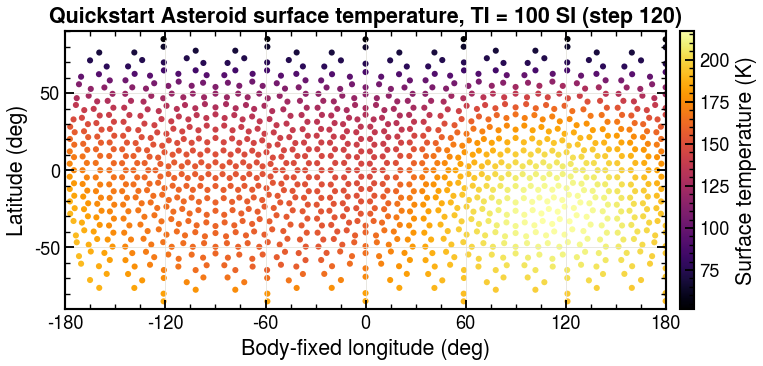

Step 120: T range 51.9-216.7 K (713 distinct values of 1280 faces)


In [16]:
EPOCH_STEP = 120  # second rotation (steps 96-191), roughly mid-afternoon local time
T_epoch = BASE.field("temperature", EPOCH_STEP)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
sc = ax.scatter(lon, lat, c=T_epoch, cmap=plots.CMAP_FIELD, s=16, edgecolors="none")
cbar = fig.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label("Surface temperature (K)")
ax.set_xlabel("Body-fixed longitude (deg)")
ax.set_ylabel("Latitude (deg)")
ax.set_title(f"Quickstart Asteroid surface temperature, TI = 100 SI (step {EPOCH_STEP})")
ax.set_xlim(-180, 180)  # mesh.ply longitude convention is [-180, 180], not [0, 360]
ax.set_ylim(-90, 90)
ax.set_xticks(range(-180, 181, 60))
ax.grid(**GRID)
plt.tight_layout()
plt.show()

print(f"Step {EPOCH_STEP}: T range {T_epoch.min():.1f}-{T_epoch.max():.1f} K "
      f"({np.unique(np.round(T_epoch, 1)).size} distinct values of {T_epoch.size} faces)")

A warm afternoon lobe, a cold night hemisphere, and — because
`pole_dec_deg = 90` pins the sub-solar latitude at the equator for the whole
run — poles at an intermediate, roughly constant temperature
(near-permanent grazing sunlight, the edge case described in the QA section
above; a consequence of this config's zero-obliquity spin).


### 5.2 Equatorial diurnal curve

The plot is temperature vs. **local solar time (LST)** — the Sun's hour angle
on a 24-hour clock with local noon = 12h, regardless of the body's actual
rotation period (the standard planetary-science convention). For each
equatorial-band face, local noon is the timestep where its `direct_solar`
flux peaks (flux has no thermal inertia, so this is exact); each face's
temperature is then binned by LST relative to its own noon. The curve is an
ensemble average over all 220 equatorial faces, so single-face
mesh-triangulation idiosyncrasies wash out. `Results.local_solar_time_curve()`
does that reduction; which output steps to feed it stays with the caller,
because "the settled rotation" is a judgement about the run.


In [17]:
def diurnal_curve(res, lat_max=10.0, n_bins=48):
    """Equatorial local-solar-time curve over the SECOND output rotation.

    Both configs here write two rotations. Periodicity between rotation 1 and
    rotation 2 was confirmed during development (max|delta T| = 0.25 K at
    50-rotation equilibration), so the second one is the settled, periodic
    rotation and is the one binned. Results.local_solar_time_curve() does the
    binning: per-face local noon is the step at which that face's
    `direct_solar` peaks, and every sample is placed on a 24-hour clock
    relative to it.
    """
    steps = res.steps("temperature")
    return res.local_solar_time_curve(lat_max=lat_max, n_bins=n_bins,
                                      steps=steps[len(steps) // 2:])


lst100, T100, lo100, hi100, n_eq100 = diurnal_curve(BASE)
print(f"{n_eq100} equatorial faces binned into {len(lst100)} local-solar-time bins")

220 equatorial faces binned into 48 local-solar-time bins


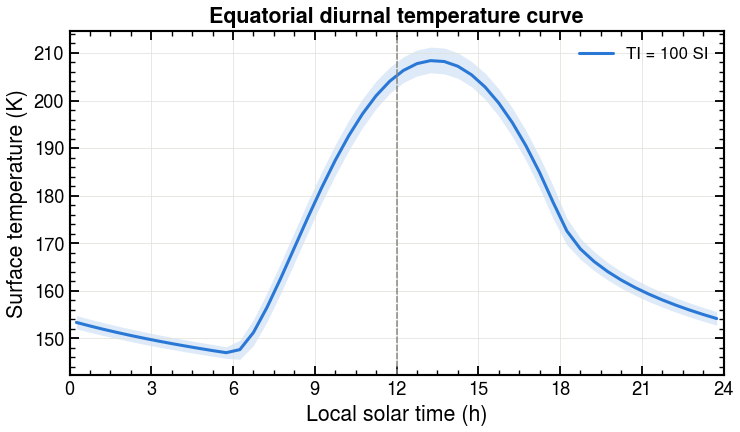

Peak temperature at LST = 13.25 h (75 min after local noon)
Diurnal amplitude (band mean Tmax - Tmin): 61.4 K


In [18]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(lst100, T100, color=BLUE, lw=2, label="TI = 100 SI")
ax.fill_between(lst100, lo100, hi100, color=BLUE, alpha=0.15, linewidth=0)
ax.axvline(12, color=GREY, lw=1, linestyle="--")
ax.set_xlabel("Local solar time (h)")
ax.set_ylabel("Surface temperature (K)")
ax.set_title("Equatorial diurnal temperature curve")
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 3))
ax.legend(frameon=False)
ax.grid(**GRID)
plt.tight_layout()
plt.show()

peak_lst_100 = lst100[np.argmax(T100)]
print(f"Peak temperature at LST = {peak_lst_100:.2f} h "
      f"({(peak_lst_100 - 12) * 60:.0f} min after local noon)")
print(f"Diurnal amplitude (band mean Tmax - Tmin): {T100.max() - T100.min():.1f} K")

The band shading is the inter-face (25th–75th percentile) spread at fixed
LST — small, so the ensemble-average curve is representative.

### 5.3 The signature plot: thermal-inertia amplitude damping and phase lag

Same construction, now overlaying the TI = 200 SI run.


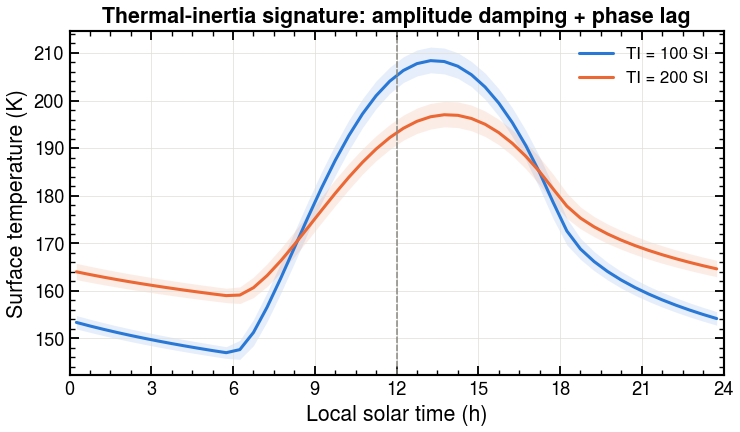

TI=100: peak LST = 13.25 h   amplitude = 61.4 K
TI=200: peak LST = 13.75 h   amplitude = 38.0 K
Peak shifted 30 minutes later; amplitude fell 23.4 K (38% reduction) at 2x the thermal inertia.


In [19]:
lst200, T200, lo200, hi200, n_eq200 = diurnal_curve(TI200)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(lst100, T100, color=BLUE, lw=2, label="TI = 100 SI")
ax.fill_between(lst100, lo100, hi100, color=BLUE, alpha=0.12, linewidth=0)
ax.plot(lst200, T200, color=ORANGE, lw=2, label="TI = 200 SI")
ax.fill_between(lst200, lo200, hi200, color=ORANGE, alpha=0.12, linewidth=0)
ax.axvline(12, color=GREY, lw=1, linestyle="--")
ax.set_xlabel("Local solar time (h)")
ax.set_ylabel("Surface temperature (K)")
ax.set_title("Thermal-inertia signature: amplitude damping + phase lag")
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 3))
ax.legend(frameon=False)
ax.grid(**GRID)
plt.tight_layout()
plt.show()

peak_lst_200 = lst200[np.argmax(T200)]
amp100 = T100.max() - T100.min()
amp200 = T200.max() - T200.min()
print(f"TI=100: peak LST = {peak_lst_100:.2f} h   amplitude = {amp100:.1f} K")
print(f"TI=200: peak LST = {peak_lst_200:.2f} h   amplitude = {amp200:.1f} K")
print(f"Peak shifted {(peak_lst_200 - peak_lst_100) * 60:.0f} minutes later; "
      f"amplitude fell {amp100 - amp200:.1f} K "
      f"({100 * (amp100 - amp200) / amp100:.0f}% reduction) at 2x the thermal inertia.")

**The lag shows clearly at this TI**: the peak moves from LST ≈ 13.25 h
to LST ≈ 13.75 h (about half an hour later, on this notebook's measured run)
as TI doubles, and the whole curve visibly flattens toward the mean. Both
are the textbook thermal-inertia signature (Spencer et al. 1989).

### 5.4 Quantifying the asymmetry directly

A second way to look at the same effect: for a range of offsets $x$ hours
from local noon, plot $T(\text{noon}+x) - T(\text{noon}-x)$. A perfectly
symmetric (zero-thermal-inertia) surface would give exactly zero everywhere;
any positive value is the thermal lag.


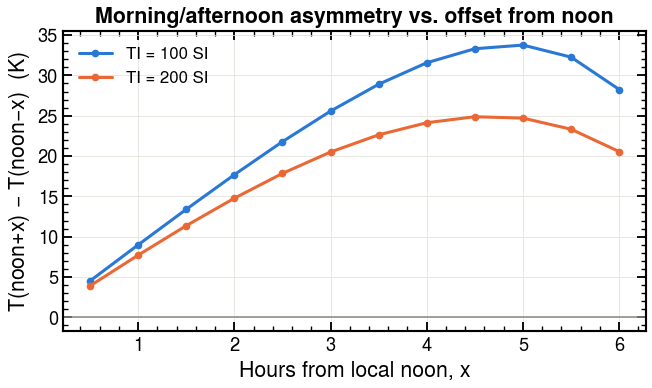

Asymmetry (K) at x = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0]
  TI=100: [4.5, 9.0, 13.4, 17.7, 21.8, 25.6, 28.9, 31.6, 33.3, 33.8, 32.3, 28.2]
  TI=200: [3.9, 7.7, 11.4, 14.8, 17.8, 20.5, 22.6, 24.1, 24.9, 24.7, 23.3, 20.5]


In [20]:
def asymmetry(lst, T):
    x = np.linspace(0.5, 6.0, 12)
    return x, np.interp(12 + x, lst, T, period=24) - np.interp(12 - x, lst, T, period=24)


x100, d100 = asymmetry(lst100, T100)
x200, d200 = asymmetry(lst200, T200)

fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.plot(x100, d100, color=BLUE, lw=2, marker="o", ms=4, label="TI = 100 SI")
ax.plot(x200, d200, color=ORANGE, lw=2, marker="o", ms=4, label="TI = 200 SI")
ax.axhline(0, color=GREY, lw=1)
ax.set_xlabel("Hours from local noon, x")
ax.set_ylabel(r"T(noon+x) $-$ T(noon$-$x)  (K)")
ax.set_title("Morning/afternoon asymmetry vs. offset from noon")
ax.legend(frameon=False)
ax.grid(**GRID)
plt.tight_layout()
plt.show()

print("Asymmetry (K) at x =", np.round(x100, 1).tolist())
print("  TI=100:", np.round(d100, 1).tolist())
print("  TI=200:", np.round(d200, 1).tolist())

Both curves are positive everywhere (afternoon warmer than the
time-mirrored morning — the correct sign), and the TI = 200 curve sits
*below* the TI = 100 curve at every offset. The peak occurs later in
absolute LST at higher TI (Section 5.3), but the *absolute* K-scale
asymmetry also depends on the overall diurnal amplitude, which falls faster
(61 K → 38 K) than the phase lag grows over this TI range. A larger phase
lag therefore does not imply a larger absolute morning/afternoon temperature
difference — the two effects partially offset, which is why real
thermophysical fits use the *whole* diurnal curve shape (amplitude and phase
together via a dimensionless thermal parameter, Section 6), not a single
asymmetry number, to solve for TI.


### 5.5 A note on thermal lightcurves

Real asteroid thermal *lightcurves* — disk-integrated flux modulating as a
non-spherical, rotating body turns a changing silhouette and thermal state
toward the observer — are a shape effect as much as a thermophysical one.
This tutorial's body is a perfect sphere with uniform properties, so there
is no lightcurve signal to show: a "sub-observer temperature vs. rotation
phase" plot on this body would just relabel Section 5.2's diurnal curve. To
build a real one, load a non-spherical DAMIT shape
(`generic_body.shape.type: custom_mesh`) and repeat Section 5.2's
construction using each face's *distance-corrected,
viewing-geometry-weighted* emission — a thermal lightcurve needs shape, not
just thermal inertia.


## 6. Interpretation

**Thermal inertia, physically.** $TI = \sqrt{k\rho c_p}$ sets how far a
diurnal thermal wave penetrates before the next day/night flip reverses it
(the diurnal skin depth $\ell_s = \sqrt{\kappa P/\pi}$, with $\kappa = k/(\rho
c_p)$ and $P$ the rotation period — about 6.3 mm for this tutorial's TI = 100
config at its 5 h spin period). A dimensionless combination, the **thermal
parameter**

$$\Theta = \frac{TI\sqrt{\omega}}{\varepsilon\sigma T_{eq}^3}$$

(Spencer, Lebofsky & Sykes 1989; $\omega$ = rotation rate, $T_{eq}$ = the
zero-inertia subsolar equilibrium temperature), governs the whole diurnal
curve shape: $\Theta \to 0$ is an instantaneous-equilibrium ("fluffy dust")
surface with a huge day/night swing and zero lag; $\Theta \to \infty$ is
perfectly conductive with **no** diurnal variation at all and (in the limit)
the peak lags all the way to a quarter-rotation. Our TI = 100 → 200 pair is a
finite step along that curve — exactly what Section 5 measured.

**The Yarkovsky connection.** Because the temperature peak lags local noon,
the asteroid re-radiates more thermal photons from its *afternoon* hemisphere
than a naive instantaneous-equilibrium body would — and photon emission
carries momentum. For a body spinning the way this tutorial's config does
(spin pole roughly normal to the orbit, i.e. an ordinary prograde equatorial
rotator), that recoil has a small component *along* the orbital velocity,
which over millions of years measurably drifts the semi-major axis outward
(inward for a retrograde rotator) — the Yarkovsky effect (Bottke et al. 2006).
Thermal inertia is the parameter that sets how large this effect is: TI → 0
or TI → ∞ both suppress it (no lag, or no asymmetry left to lag), and it
peaks at intermediate TI — the same $\Theta \sim 1$ regime real small NEAs
often sit in, which is exactly why Yarkovsky-drift modeling and thermal-
inertia measurement are the same scientific problem in practice.

**Connection to real observations.** Nothing in this notebook is
observational, but the pipeline it demonstrates is the actual one: ground-
and space-based thermal-infrared photometry (radiometry) measures a disk-
integrated flux at one or more wavelengths and rotational phases; a
thermophysical model — structurally the same conduction solve as this
tutorial's config, just fit to real shape/spin/albedo — is run over a grid of
candidate thermal inertias, and the TI that reproduces the observed flux
(amplitude *and* phase, per Section 5.4's lesson) is reported. The same
physics underlies flyby/rendezvous thermal-IR imaging, which measures
`T(local time)` directly, the way Section 5.2's plot does, rather than only a
disk-integrated number.

## 7. Exercises

Set `RUN_EXERCISES = True` in the cell below to execute these (each launches
1–4 more ~25–35 s CPU runs; left off by default so re-running this notebook
top-to-bottom stays fast). All three reuse `run_ptm()`, `diurnal_curve()` and
`ptm.Results` from above.

In [21]:
RUN_EXERCISES = False  # flip to True to actually launch the runs below


def write_variant(overrides, out_name):
    """Copy the base config with {dotted.path: value} overrides applied.

    Writes examples/<out_name>.yaml and returns (relative config path, a
    Results-ready output directory).
    """
    cfg = yaml.safe_load(
        (REPO_ROOT / "examples" / "quickstart_asteroid_diurnal.yaml").read_text())
    for dotted, value in overrides.items():
        node, keys = cfg, dotted.split(".")
        for k in keys[:-1]:
            node = node[k]
        node[keys[-1]] = value
    cfg["output"]["directory"] = f"output/{out_name}"
    out_path = REPO_ROOT / "examples" / f"{out_name}.yaml"
    out_path.write_text(yaml.safe_dump(cfg, sort_keys=False))
    return f"examples/{out_name}.yaml", REPO_ROOT / "output" / out_name


print("RUN_EXERCISES =", RUN_EXERCISES)

RUN_EXERCISES = False


### Exercise 1 — Vary thermal inertia

Sweep `ks`/`kd` (hence TI) over the rule-of-thumb range from Section 2
(~32–316 SI) and plot amplitude and peak-LST vs. TI. Recall $TI \propto
\sqrt{ks}$ at fixed `rhos`/`cp0`, so hitting TI = {32, 100, 316} needs `ks`
= TI²/(1500·800) = {0.000853, 0.008333, 0.0833} W/m/K. Outside this range,
runs may crash or converge slowly (very low TI: sub-mm skin depth; very
high TI: slow equilibration) — the numerical edge cases noted in Section 2.


In [22]:
if RUN_EXERCISES:
    TI_targets = [32.0, 100.0, 200.0, 316.0]
    rhos, cp0 = 1500.0, 800.0
    results = []
    for TI in TI_targets:
        ks = TI ** 2 / (rhos * cp0)
        cfg_rel, out_dir = write_variant(
            {"generic_body.surface.ks": ks, "generic_body.surface.kd": ks},
            f"_ex1_ti{int(TI)}")
        run_ptm(cfg_rel, f"TI={TI:.0f}")
        lst, T, lo, hi, n = diurnal_curve(Results(out_dir, body_radius_km=5.0))
        results.append((TI, T.max() - T.min(), lst[np.argmax(T)]))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
    TIs, amps, peaks = zip(*results)
    ax1.plot(TIs, amps, "o-", color=BLUE)
    ax1.set_xlabel("Thermal inertia (SI)"); ax1.set_ylabel("Diurnal amplitude (K)")
    ax2.plot(TIs, peaks, "o-", color=ORANGE)
    ax2.set_xlabel("Thermal inertia (SI)"); ax2.set_ylabel("Peak local solar time (h)")
    for ax in (ax1, ax2):
        ax.grid(**GRID)
    plt.tight_layout(); plt.show()
else:
    print("Skipped (RUN_EXERCISES = False).")

Skipped (RUN_EXERCISES = False).


### Exercise 2 — Vary spin rate

Change `generic_body.spin.period_hours` (try 2 h and 10 h) at fixed TI = 100.
What matters for the diurnal curve is not TI alone but the thermal parameter
$\Theta \propto TI\sqrt{\omega}$ (Section 6) — a faster spin raises $\omega$
and therefore $\Theta$ *even at the same TI*, so a 2 h rotator should show
**more** damping than the 5 h baseline, and a 10 h rotator **less**. Remember
to also lower `equilibration_steps_per_day` proportionally if you shorten the
period drastically, so the pinned per-rotation sample count doesn't
implicitly change.

In [23]:
if RUN_EXERCISES:
    for period_h in (2.0, 10.0):
        n_rot_steps = 48  # keep the same steps/rotation as the baseline
        cfg_rel, out_dir = write_variant(
            {"generic_body.spin.period_hours": period_h,
             "simulation.duration_days": 2 * period_h / 24.0,
             "simulation.timesteps": 2 * n_rot_steps,
             "thermal.equilibration_steps_per_day": n_rot_steps * 24.0 / period_h},
            f"_ex2_period{int(period_h)}h")
        run_ptm(cfg_rel, f"period={period_h:.0f}h")
        lst, T, lo, hi, n = diurnal_curve(Results(out_dir, body_radius_km=5.0))
        print(f"  period={period_h:.0f} h: amplitude={T.max()-T.min():.1f} K, "
              f"peak LST={lst[np.argmax(T)]:.2f} h")
else:
    print("Skipped (RUN_EXERCISES = False).")

Skipped (RUN_EXERCISES = False).


### Exercise 3 — Add eccentricity

Set `generic_body.orbit.eccentricity` to, say, 0.2. Note that this
tutorial's 2-rotation (~10-hour) output window is far too short to show any
effect of eccentricity: heliocentric distance barely changes over a few
hours of an ~4.4-year orbit (`semi_major_axis_au = 2.7`). The edit only
becomes visible if `simulation.duration_days` is extended to a sizeable
fraction of the orbital period, well outside laptop-tutorial cost. This
exercise is a pointer, not a to-run-here cell: try a duration of a few
percent of the orbital period and look for a slowly-drifting mean
temperature riding on top of the same diurnal cycle.


## Version

This notebook was executed end to end (`jupyter nbconvert --execute`)
against the binary and commit printed in Section 1, in the `europa_viz`
conda environment. The model is deterministic given the config, so
re-running from a clean clone reproduces the same runs and plots; exact K
values can drift with build-to-build engine changes (see
[Tutorial 02](../02_lunar_diurnal_icosphere.md)), which is why Section 3's
QA cells check *signal* and *sign* rather than hard-coded numbers.
